Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 130, 13, 16)         │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 65, 6, 16)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 65, 6, 32)           │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 32, 3, 32)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │          98,336 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 103,169 (403.00 KB)

 Trainable params: 103,169 (403.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.5866 - loss: 0.6811 - val_accuracy: 0.6556 - val_loss: 0.5897
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7318 - loss: 0.5528 - val_accuracy: 0.6556 - val_loss: 0.5821
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7933 - loss: 0.4463 - val_accuracy: 0.7444 - val_loss: 0.4433
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8296 - loss: 0.3697 - val_accuracy: 0.8222 - val_loss: 0.4089
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8771 - loss: 0.2976 - val_accuracy: 0.8444 - val_loss: 0.3194
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8911 - loss: 0.2576 - val_accuracy: 0.8556 - val_loss: 0.3089
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9078 - loss: 0.2192 - val_accuracy: 0.9000 - val_loss: 0.2813
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9441 - loss: 0.1652 - val_accuracy: 0.

CNN Model Test Accuracy: 0.875


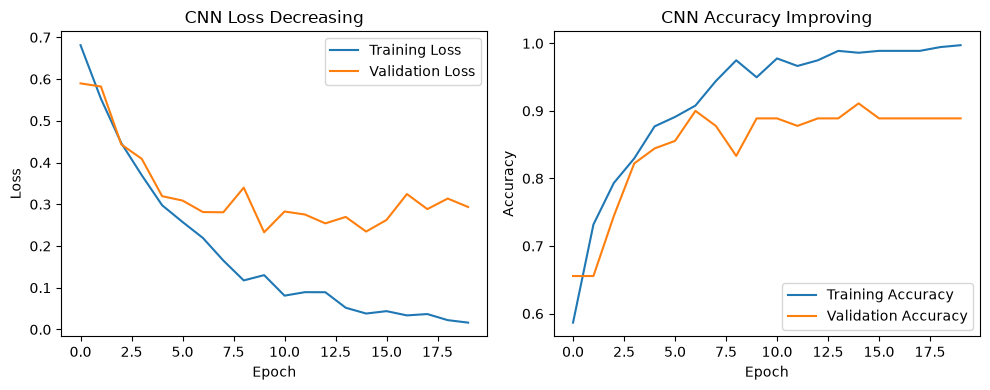

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

X_train = np.load("../data/X_cnn_train.npy")
X_test = np.load("../data/X_cnn_test.npy")
y_train = np.load("../data/y_train.npy")
y_test = np.load("../data/y_test.npy")

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1], X_train.shape[2], 1)),

    # First Convolution + Pooling block
    layers.Conv2D(16, (3,3), activation="relu", padding="same"),  # ACTIVATION: ReLU
    layers.MaxPooling2D((2,2)),                                   # POOLING LAYER 1

    # Second Convolution + Pooling block
    layers.Conv2D(32, (3,3), activation="relu", padding="same"),  # ACTIVATION: ReLU
    layers.MaxPooling2D((2,2)),                                   # POOLING LAYER 2

    layers.Flatten(),          # converts the shrunk image into a flat list of numbers
    layers.Dense(32, activation="relu"),   # ACTIVATION: ReLU
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")  # ACTIVATION: Sigmoid (final output)
])

model.summary()

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)


test_loss, test_acc = model.evaluate(X_test, y_test)
print("CNN Model Test Accuracy:", test_acc)

model.save("../models/cnn_model.h5")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Loss Decreasing')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Accuracy Improving')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.tight_layout()
plt.savefig("../data/cnn_training_plot.png")
plt.show()